# Urban Pulse: exploring NYC 311 requests, January to June 2025

This notebook goes through the 15 questions of the project on a sample of about 105,000 NYC 311 service requests created between 1 January and 30 June 2025. The data was cleaned in `src/clean.py` and loaded into PostgreSQL (`service_requests`); the queries below are the same ones as in `sql/analysis.sql`, run through pandas.

Each question has the query, the sample size, one chart, and two short notes. "Observed" only repeats what the numbers show. "Careful reading" says what the numbers cannot tell us. A few things apply to every section: this is a sample of reported requests, not all problems in the city; a closed date is a date an agency recorded, not proof that the problem was fixed or that the person was satisfied; the 72 hour line is a cut-off I chose for the project, not an official target; and the agencies deal with very different kinds of work, so comparing them directly is risky.

## Setup

In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sqlalchemy import text
from dotenv import load_dotenv

sys.path.append("../src")
load_dotenv("../.env")
from db import get_engine

engine = get_engine()
pd.set_option("display.width", 120)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

def q(sql):
    return pd.read_sql(text(sql), engine)

# quick look at the table before any question
q("SELECT COUNT(*) AS rows_in_table, MIN(created_date) AS first_created, MAX(created_date) AS last_created FROM service_requests")

,rows_in_table,first_created,last_created
0,105540,2025-01-01 00:00:19,2025-06-30 23:59:24


## 1. How many requests are in the sample?

n = 105540
closed: 104153  valid resolution time: 104115


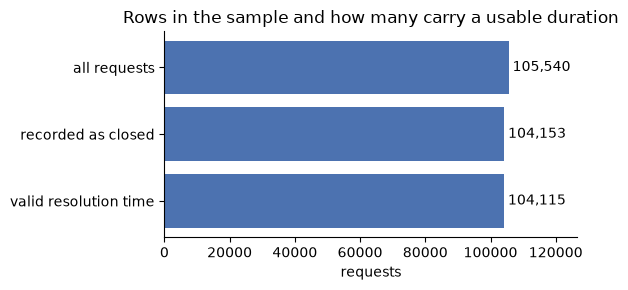

In [2]:
total_requests = q("""
SELECT COUNT(DISTINCT unique_key) AS total_requests
FROM service_requests
""").iloc[0, 0]
print("n =", total_requests)

# how many of those can be used for a resolution time
usable = q("""
SELECT COUNT(*) FILTER (WHERE is_closed) AS closed,
       COUNT(resolution_hours)            AS valid_resolution
FROM service_requests
""")
closed_rows = int(usable.closed[0])
valid_rows = int(usable.valid_resolution[0])
print("closed:", closed_rows, " valid resolution time:", valid_rows)

fig, ax = plt.subplots(figsize=(6, 3))
labels = ["all requests", "recorded as closed", "valid resolution time"]
vals = [total_requests, closed_rows, valid_rows]
ax.barh(labels[::-1], vals[::-1], color="#4c72b0")
for i, v in enumerate(vals[::-1]):
    ax.text(v, i, f" {v:,}", va="center")
ax.set_xlim(0, total_requests * 1.2)
ax.set_xlabel("requests")
ax.set_title("Rows in the sample and how many carry a usable duration")
plt.tight_layout()
plt.show()

**Observed.** The table holds 105,540 distinct requests, which matches the raw file (nothing was dropped in cleaning). 104,153 of them are recorded as closed, and 104,115 have a usable resolution time. The 38 rows lost between those two numbers are requests whose closed date is earlier than the created date.

**Careful reading.** This is a sample window of six months, so 105,540 is not the yearly volume and not the full 311 load. The sample was not drawn to be representative of anything beyond that window.

## 2. Which ten complaint types come up most often?

n = 105540 | rows in the top 10: 61633
share of the top 10: 58.4 %


,complaint_type,requests,pct
0,Illegal Parking,17251,16.3
1,Noise - Residential,13022,12.3
2,HEAT/HOT WATER,9799,9.3
3,Blocked Driveway,5030,4.8
4,Noise - Street/Sidewalk,4420,4.2
5,UNSANITARY CONDITION,3173,3.0
6,Street Condition,2393,2.3
7,Water System,2298,2.2
8,PLUMBING,2221,2.1
9,Noise - Commercial,2026,1.9


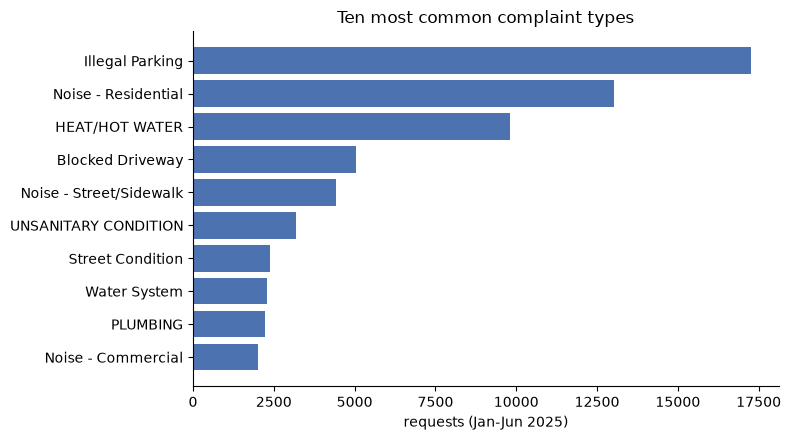

In [3]:
top_complaints = q("""
SELECT complaint_type, COUNT(*) AS requests,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct
FROM service_requests
GROUP BY complaint_type
ORDER BY requests DESC
LIMIT 10
""")
print("n =", total_requests, "| rows in the top 10:", top_complaints.requests.sum())
print("share of the top 10:", round(top_complaints.pct.sum(), 1), "%")
display(top_complaints)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top_complaints.complaint_type[::-1], top_complaints.requests[::-1], color="#4c72b0")
ax.set_xlabel("requests (Jan-Jun 2025)")
ax.set_title("Ten most common complaint types")
plt.tight_layout()
plt.show()

**Observed.** Illegal Parking is first with 17,251 requests (16.3%), then Noise - Residential with 13,022 (12.3%) and HEAT/HOT WATER with 9,799 (9.3%). The top ten together cover 58.4% of all requests. Three of the ten are noise types (residential, street/sidewalk, commercial) and together they make up about 18% of the sample.

**Careful reading.** These are counts of what people chose to report, so they say what is reported often, not what is the biggest problem. Complaint types are the categories the city uses; some overlap (Blocked Driveway and Illegal Parking, for example), which splits one kind of problem over several rows. I merged 150 rows that differed only in letter case, but I did not merge categories by meaning.

## 3. How is the work split between agencies?

n = 105540 | agencies: 14


,agency,requests,pct
0,NYPD,49003,46.4
1,HPD,22882,21.7
2,DSNY,9662,9.2
3,DOT,6676,6.3
4,DEP,5546,5.3
5,DOB,2885,2.7
6,DPR,2872,2.7
7,DOHMH,2482,2.4
8,DHS,1334,1.3
9,TLC,1004,1.0


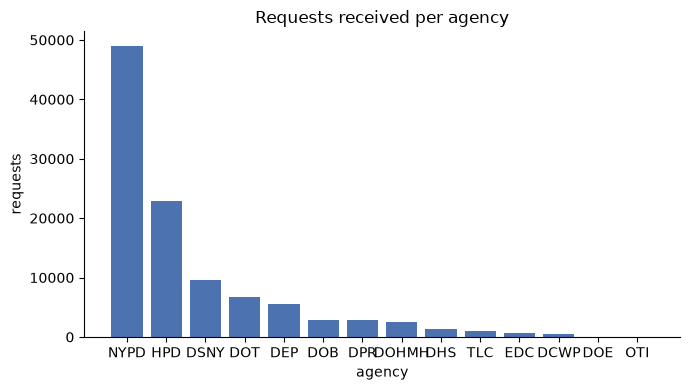

In [4]:
by_agency = q("""
SELECT agency, COUNT(*) AS requests,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct
FROM service_requests
GROUP BY agency
ORDER BY requests DESC
""")
print("n =", by_agency.requests.sum(), "| agencies:", len(by_agency))
display(by_agency)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(by_agency.agency, by_agency.requests, color="#4c72b0")
ax.set_xlabel("agency")
ax.set_ylabel("requests")
ax.set_title("Requests received per agency")
plt.tight_layout()
plt.show()

**Observed.** 14 agencies appear. NYPD received 49,003 requests (46.4%) and HPD 22,882 (21.7%); DSNY is third with 9,662 (9.2%). These three hold about 77% of the sample. At the other end, DOE has 61 requests and OTI only 6.

**Careful reading.** The agency is the one the request was routed to, and it follows from the complaint type, so this chart mostly repeats question 2 (parking and noise go to NYPD, heat and plumbing to HPD). A big share here means 311 is used a lot for that kind of problem, not that the agency does a lot more work than the others.

## 4. How do the boroughs compare in volume?

n = 105540


,borough,requests,pct
0,BROOKLYN,31634,30.0
1,QUEENS,24954,23.6
2,BRONX,24072,22.8
3,MANHATTAN,20835,19.7
4,STATEN ISLAND,3970,3.8
5,Unspecified,75,0.1


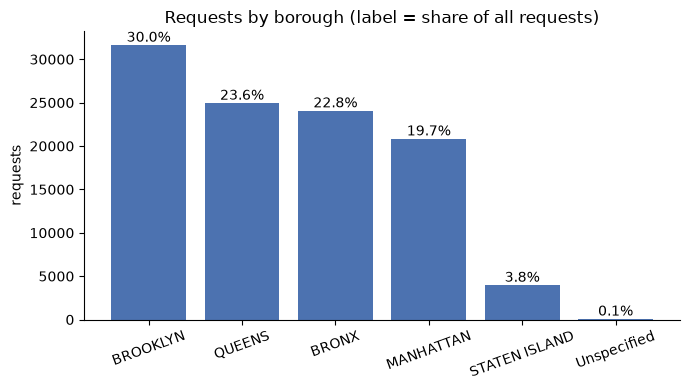

In [5]:
by_borough = q("""
SELECT borough, COUNT(*) AS requests,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct
FROM service_requests
GROUP BY borough
ORDER BY requests DESC
""")
print("n =", by_borough.requests.sum())
display(by_borough)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(by_borough.borough, by_borough.requests, color="#4c72b0")
ax.bar_label(bars, labels=[f"{p}%" for p in by_borough.pct])
ax.set_ylabel("requests")
ax.set_title("Requests by borough (label = share of all requests)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Observed.** Brooklyn has the most requests (31,634, 30.0%), followed by Queens (24,954, 23.6%), the Bronx (24,072, 22.8%) and Manhattan (20,835, 19.7%). Staten Island has 3,970 (3.8%). 75 requests have the borough 'Unspecified'.

**Careful reading.** These are raw counts. I did not divide by population or by number of housing units, so I cannot say that Brooklyn has a worse problem per resident. Borough also depends on the address being recorded properly, which is why 75 rows are unspecified.

## 5. Does volume change from month to month?

n = 105540


,month,requests,per_day
0,2025-01,20902,674.0
1,2025-02,15336,548.0
2,2025-03,16901,545.0
3,2025-04,16401,547.0
4,2025-05,17661,570.0
5,2025-06,18339,611.0


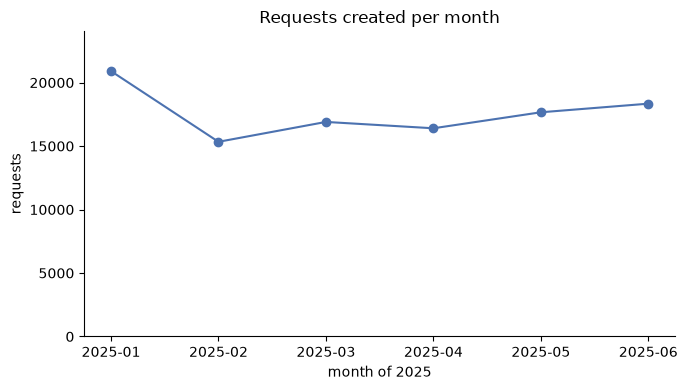

In [6]:
monthly = q("""
SELECT created_year_month AS month, COUNT(*) AS requests
FROM service_requests
GROUP BY created_year_month
ORDER BY month
""")
print("n =", monthly.requests.sum())
monthly["per_day"] = (monthly.requests / pd.PeriodIndex(monthly.month, freq="M").days_in_month).round(0)
display(monthly)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(monthly.month, monthly.requests, marker="o", color="#4c72b0")
ax.set_ylim(0, monthly.requests.max() * 1.15)
ax.set_xlabel("month of 2025")
ax.set_ylabel("requests")
ax.set_title("Requests created per month")
plt.tight_layout()
plt.show()

**Observed.** January is the highest month with 20,902 requests, February the lowest with 15,336. After that the count rises again: 16,901 in March, 16,401 in April, 17,661 in May and 18,339 in June. Because the months have different lengths I also looked at requests per day: about 674 in January, 548 in February, 545 in March, 547 in April, 570 in May and 611 in June.

**Careful reading.** Six months is too short to call anything a season. January may be high because of cold-weather complaints, but I did not check that here, and one year cannot show whether the same pattern repeats. The sample only starts on 1 January 2025, so there is no earlier month to compare with.

## 6. When during the week are requests created?

n = 105540


,created_weekday_num,created_weekday,created_hour,requests
10,0,Monday,10,1026
107,4,Friday,11,1026
9,0,Monday,9,1010
11,0,Monday,11,960
35,1,Tuesday,11,958


created_weekday
Monday       15640
Tuesday      15337
Wednesday    15717
Thursday     15570
Friday       15472
Saturday     13823
Sunday       13981
dtype: int64
busiest hours: {11: 6211, 10: 6201, 9: 6093}
quietest hours: {4: 1254, 3: 1388, 5: 1482}
share created 8:00-17:59: 54.4 %


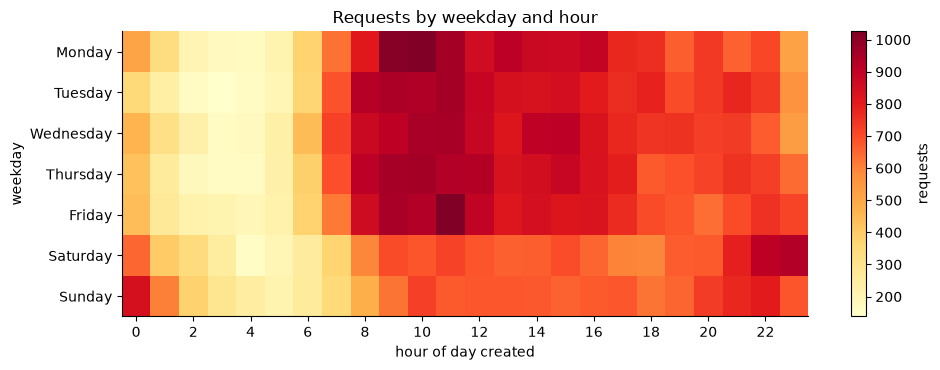

In [7]:
weekday_hour = q("""
SELECT created_weekday_num, created_weekday, created_hour, COUNT(*) AS requests
FROM service_requests
GROUP BY created_weekday_num, created_weekday, created_hour
ORDER BY created_weekday_num, created_hour
""")
print("n =", weekday_hour.requests.sum())

grid = weekday_hour.pivot(index="created_weekday", columns="created_hour", values="requests")
order = weekday_hour.drop_duplicates("created_weekday").sort_values("created_weekday_num").created_weekday
grid = grid.loc[order]
busiest = weekday_hour.sort_values("requests", ascending=False).head(5)
display(busiest)
print(grid.sum(axis=1))
by_hour = grid.sum()
print("busiest hours:", by_hour.sort_values(ascending=False).head(3).to_dict())
print("quietest hours:", by_hour.sort_values().head(3).to_dict())
print("share created 8:00-17:59:", round(100 * by_hour.loc[8:17].sum() / by_hour.sum(), 1), "%")

fig, ax = plt.subplots(figsize=(10, 3.8))
im = ax.imshow(grid.values, aspect="auto", cmap="YlOrRd")
ax.set_yticks(range(len(grid.index)), grid.index)
ax.set_xticks(range(0, 24, 2), range(0, 24, 2))
ax.set_xlabel("hour of day created")
ax.set_ylabel("weekday")
ax.set_title("Requests by weekday and hour")
fig.colorbar(im, ax=ax, label="requests")
plt.tight_layout()
plt.show()

**Observed.** Weekdays are close to each other (between 15,337 on Tuesday and 15,717 on Wednesday), and Saturday and Sunday are lower at 13,823 and 13,981. The busiest hours are 11 (6,211 requests), 10 (6,201) and 9 (6,093); the quietest are 4 (1,254), 3 (1,388) and 5 (1,482). 54.4% of requests are created between 08:00 and 17:59. The two single busiest cells are Monday 10:00 and Friday 11:00 with 1,026 each.

**Careful reading.** The hour is when the request was created in the system, not when the problem happened. Phone, app and web requests are mixed together, and I did not split by channel, so a weekday morning peak could come from how people call rather than from when problems appear. Time zone is taken as it came in the source.

## 7. What status do requests have?

n = 105540


,status,requests,pct
0,Closed,104420,98.94
1,In Progress,699,0.66
2,Open,194,0.18
3,Pending,138,0.13
4,Assigned,66,0.06
5,Started,21,0.02
6,Unspecified,2,0.00


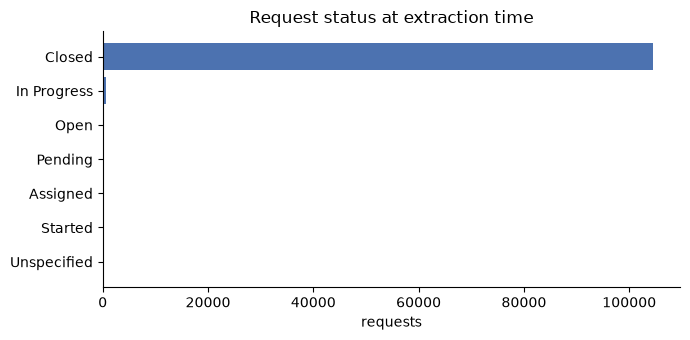

In [8]:
status_counts = q("""
SELECT status, COUNT(*) AS requests,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
FROM service_requests
GROUP BY status
ORDER BY requests DESC
""")
print("n =", status_counts.requests.sum())
display(status_counts)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(status_counts.status[::-1], status_counts.requests[::-1], color="#4c72b0")
ax.set_xlabel("requests")
ax.set_title("Request status at extraction time")
plt.tight_layout()
plt.show()

**Observed.** 104,420 requests (98.94%) have the status Closed. The rest are In Progress (699), Open (194), Pending (138), Assigned (66), Started (21) and Unspecified (2).

**Careful reading.** The data was pulled long after the six-month window (the extraction date is in the cleaning log), so a high closed share is expected. The status field and the closed date do not always agree: 352 rows say Closed with no closed date and 85 have a date but another status, which is why 'closed' in question 1 is 104,153 and not 104,420. Closed only means the agency ended the case.

## 8. How long does a request take to close? (descriptive statistics)

n = 104115


,0
n,104115.00
mean,261.79
median,7.80
mode_whole_hours,1.00
min,0.00
max,15567.60
q1,1.13
q3,66.94
std_dev,1008.10
variance,1016215.00


share over 72 h: 23.9 %


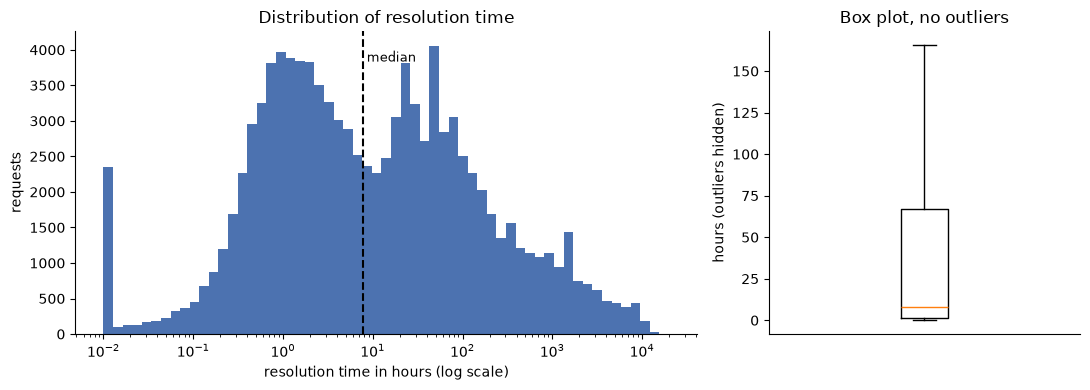

In [9]:
resolution_stats = q("""
SELECT COUNT(resolution_hours)                                           AS n,
       ROUND(AVG(resolution_hours)::numeric, 2)                          AS mean,
       ROUND((PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY resolution_hours))::numeric, 2) AS median,
       ROUND((MODE() WITHIN GROUP (ORDER BY ROUND(resolution_hours::numeric, 0)))::numeric, 0) AS mode_whole_hours,
       ROUND(MIN(resolution_hours)::numeric, 2)                          AS min,
       ROUND(MAX(resolution_hours)::numeric, 1)                          AS max,
       ROUND((PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY resolution_hours))::numeric, 2) AS q1,
       ROUND((PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY resolution_hours))::numeric, 2) AS q3,
       ROUND(STDDEV_SAMP(resolution_hours)::numeric, 1)                  AS std_dev,
       ROUND(VAR_SAMP(resolution_hours)::numeric, 0)                     AS variance
FROM service_requests
WHERE resolution_hours IS NOT NULL
""")
print("n =", resolution_stats.n[0])
display(resolution_stats.T)

hours = q("SELECT resolution_hours FROM service_requests WHERE resolution_hours IS NOT NULL").resolution_hours
print("share over 72 h:", round((hours > 72).mean() * 100, 1), "%")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [2, 1]})
# log axis, zeros pushed to 0.01 h so they show up in the first bin
ax1.hist(hours.clip(lower=0.01), bins=np.logspace(-2, 4.3, 60), color="#4c72b0")
ax1.set_xscale("log")
ax1.axvline(hours.median(), color="black", linestyle="--")
ax1.text(hours.median() * 1.1, ax1.get_ylim()[1] * 0.9, "median", fontsize=9)
ax1.set_xlabel("resolution time in hours (log scale)")
ax1.set_ylabel("requests")
ax1.set_title("Distribution of resolution time")
ax2.boxplot(hours, orientation="vertical", showfliers=False)
ax2.set_ylabel("hours (outliers hidden)")
ax2.set_xticks([])
ax2.set_title("Box plot, no outliers")
plt.tight_layout()
plt.show()

**Observed.** Of the 104,115 valid resolution times the mean is 261.79 hours but the median is only 7.80 hours. The most common whole-hour value is 1. The quartiles are 1.13 and 66.94 hours, the largest value is 15,567.6 hours (about 650 days) and the standard deviation is 1,008.1, almost four times the mean. 23.9% take longer than 72 hours. The histogram has a small spike at the very left: these are requests closed at the same second they were created.

**Careful reading.** With a distribution like this the mean is not a typical request; the median and the quartiles are the better summary. I plotted on a log scale, so the shape looks more even than it is. The spike at zero is the 2,174 rows flagged as closed at creation in the cleaning log; I kept them, but they look like automatic closing and not real work done in zero time.

## 9. Which complaint types take longest to close?

n = 102472 valid cases in 82 categories with 100+


,complaint_type,n,median_hours
0,Noise - Helicopter,536,7592.6
1,Taxi Complaint,218,2717.4
2,For Hire Vehicle Complaint,503,1905.3
3,Building/Use,606,1822.8
4,Food Establishment,366,1441.0
5,Smoking or Vaping,172,1441.0
6,Mobile Food Vendor,157,1440.4
7,Root/Sewer/Sidewalk Condition,256,1225.5
8,Special Projects Inspection Team (SPIT),127,735.2
9,Elevator,641,581.6


,complaint_type,n,median_hours
77,Noise - Park,279,0.8
78,Traffic,337,0.5
79,Drug Activity,693,0.4
80,Vendor Enforcement,776,0.3
81,Rodent,986,0.0


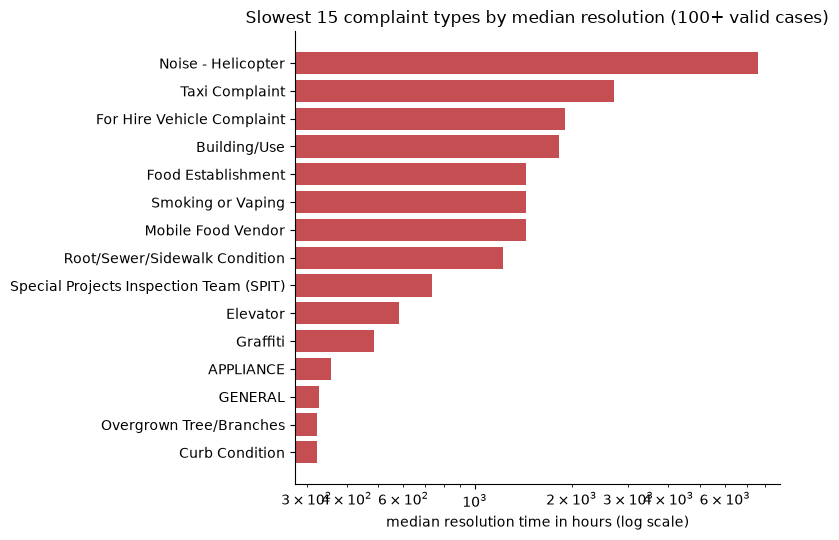

In [10]:
by_complaint = q("""
SELECT complaint_type, COUNT(resolution_hours) AS n,
       ROUND((PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY resolution_hours))::numeric, 1) AS median_hours
FROM service_requests
WHERE resolution_hours IS NOT NULL
GROUP BY complaint_type
HAVING COUNT(resolution_hours) >= 100
ORDER BY median_hours DESC
""")
by_complaint["median_hours"] = by_complaint.median_hours.astype(float)
print("n =", by_complaint.n.sum(), "valid cases in", len(by_complaint), "categories with 100+")
display(by_complaint.head(12))
display(by_complaint.tail(5))

shown = by_complaint.head(15)
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(shown.complaint_type[::-1], shown.median_hours[::-1], color="#c44e52")
ax.set_xscale("log")
ax.set_xlabel("median resolution time in hours (log scale)")
ax.set_title("Slowest 15 complaint types by median resolution (100+ valid cases)")
plt.tight_layout()
plt.show()

**Observed.** 82 complaint types have 100 or more valid cases. Noise - Helicopter has the longest median, 7,592.6 hours (536 cases), followed by Taxi Complaint (2,717.4 h), For Hire Vehicle Complaint (1,905.3 h) and Building/Use (1,822.8 h). At the fast end, Rodent has a median of 0.0 hours, Vendor Enforcement 0.3 and Drug Activity 0.4.

**Careful reading.** A median of 7,592 hours is about 316 days, so these cases were closed long after the six-month window. For categories like this the closed date probably reflects a batch or administrative closing and not the moment a problem was solved; for Rodent and similar types a median near zero likely means the request is closed when it is logged or an inspection result is entered right away. I would not read either end as 'good' or 'bad' service. Types with fewer than 100 valid cases are left out, so rare complaints are missing.

## 10. Which agencies take longest to close requests?

n = 104049 valid cases in 12 agencies


,agency,n,median_hours
0,EDC,536,7592.6
1,TLC,934,1605.1
2,DOB,2885,266.5
3,DPR,2497,173.5
4,DCWP,508,80.9
5,HPD,22757,77.4
6,DOT,6497,39.1
7,DSNY,9582,30.1
8,DOHMH,2384,21.2
9,DEP,5483,19.5


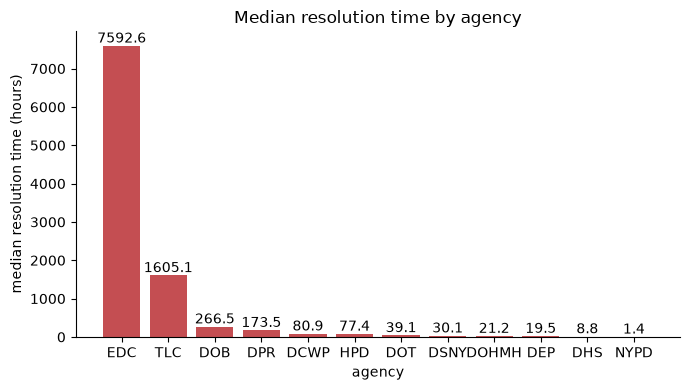

In [11]:
agency_median = q("""
SELECT agency, COUNT(resolution_hours) AS n,
       ROUND((PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY resolution_hours))::numeric, 1) AS median_hours
FROM service_requests
WHERE resolution_hours IS NOT NULL
GROUP BY agency
HAVING COUNT(resolution_hours) >= 100
ORDER BY median_hours DESC
""")
agency_median["median_hours"] = agency_median.median_hours.astype(float)
print("n =", agency_median.n.sum(), "valid cases in", len(agency_median), "agencies")
display(agency_median)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(agency_median.agency, agency_median.median_hours, color="#c44e52")
ax.bar_label(bars, fmt="%.1f")
ax.set_xlabel("agency")
ax.set_ylabel("median resolution time (hours)")
ax.set_title("Median resolution time by agency")
plt.tight_layout()
plt.show()

**Observed.** 12 agencies have 100 or more valid cases. EDC has the longest median at 7,592.6 hours, then TLC at 1,605.1 and DOB at 266.5. HPD is at 77.4 hours, DOT at 39.1, DSNY at 30.1 and DEP at 19.5. NYPD, with by far the most requests (49,003), has a median of 1.4 hours.

**Careful reading.** EDC's number is the helicopter noise category from question 9 and nothing else: its 536 valid cases and the median are identical, so EDC is a single complaint type here. Agencies handle different work (a police response, a building inspection and a sidewalk repair are not comparable), so this chart shows what kind of cases each agency gets as much as how fast it is. It is not a performance ranking.

## 11. Where do the extreme resolution times come from?

n = 104049 | high fence: 165.7 hours
above the fence: 16497 = 15.9 %


,agency,valid_cases,above_high_fence,pct_outlier,high_fence
0,HPD,22757,7773,34.2,165.7
1,DOB,2885,1590,55.1,165.7
2,DOT,6497,1561,24.0,165.7
3,DPR,2497,1279,51.2,165.7
4,DSNY,9582,1101,11.5,165.7
5,DOHMH,2384,821,34.4,165.7
6,TLC,934,728,77.9,165.7
7,DEP,5483,697,12.7,165.7
8,EDC,536,536,100.0,165.7
9,DCWP,508,212,41.7,165.7


,complaint_type,above_fence
0,UNSANITARY CONDITION,2020
1,PLUMBING,1158
2,DOOR/WINDOW,872
3,PAINT/PLASTER,852
4,GENERAL,681
5,WATER LEAK,655
6,Noise - Helicopter,536
7,For Hire Vehicle Complaint,498


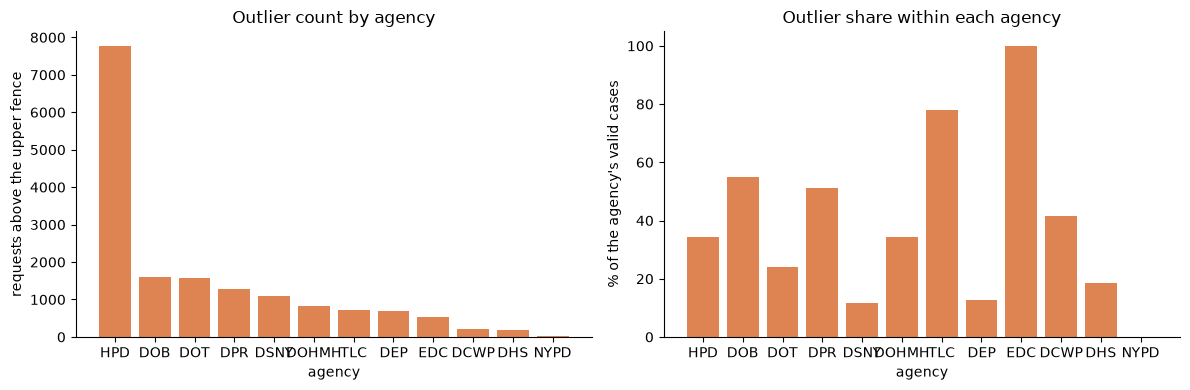

In [12]:
outliers = q("""
WITH q AS (
    SELECT PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY resolution_hours) AS q1,
           PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY resolution_hours) AS q3
    FROM service_requests
    WHERE resolution_hours IS NOT NULL
), fence AS (
    SELECT q1, q3, q3 - q1 AS iqr, q1 - 1.5 * (q3 - q1) AS low, q3 + 1.5 * (q3 - q1) AS high
    FROM q
)
SELECT s.agency,
       COUNT(*)                                                           AS valid_cases,
       COUNT(*) FILTER (WHERE s.resolution_hours > f.high)                AS above_high_fence,
       ROUND(100.0 * COUNT(*) FILTER (WHERE s.resolution_hours > f.high) / COUNT(*), 1) AS pct_outlier,
       ROUND(f.high::numeric, 1)                                          AS high_fence
FROM service_requests s CROSS JOIN fence f
WHERE s.resolution_hours IS NOT NULL
GROUP BY s.agency, f.high
HAVING COUNT(*) >= 100
ORDER BY above_high_fence DESC
""")
print("n =", outliers.valid_cases.sum(), "| high fence:", outliers.high_fence[0], "hours")
print("above the fence:", outliers.above_high_fence.sum(), "=", round(100 * outliers.above_high_fence.sum() / outliers.valid_cases.sum(), 1), "%")
display(outliers)

# which complaint types supply the outliers (same fence)
fence_hours = float(outliers.high_fence[0])
outlier_types = q(f"""
SELECT complaint_type, COUNT(*) AS above_fence
FROM service_requests
WHERE resolution_hours > {fence_hours}
GROUP BY complaint_type
ORDER BY above_fence DESC
LIMIT 8
""")
display(outlier_types)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.bar(outliers.agency, outliers.above_high_fence, color="#dd8452")
ax1.set_xlabel("agency")
ax1.set_ylabel("requests above the upper fence")
ax1.set_title("Outlier count by agency")
ax2.bar(outliers.agency, outliers.pct_outlier, color="#dd8452")
ax2.set_xlabel("agency")
ax2.set_ylabel("% of the agency's valid cases")
ax2.set_title("Outlier share within each agency")
plt.tight_layout()
plt.show()

**Observed.** The upper IQR fence is 165.7 hours. Among the 12 agencies with 100 or more valid cases, 16,497 requests (15.9%) are above it. HPD has the most, 7,773 (34.2% of its cases), then DOB with 1,590 (55.1%) and DOT with 1,561 (24.0%). EDC is at 100%, since all 536 helicopter cases are above the fence, and TLC is at 77.9%. NYPD has only 17 above the fence out of 49,003. By complaint type the most outliers are UNSANITARY CONDITION (2,020), PLUMBING (1,158) and DOOR/WINDOW (872), all housing types.

**Careful reading.** The fence is computed on all agencies together, so an agency whose normal work is slow (building inspections) will always show many 'outliers'. These are not errors or exceptions; for HPD and DOB a long time is ordinary. The totals here are for agencies with 100+ cases (104,049 rows), so they differ slightly from the 16,547 above the fence in `docs/stats_summary.json`, which counts all 104,115 valid cases.

## 12. How skewed is resolution time, and how is it spread over time bands?

n = 104115
skewness: 6.66


,band,requests,pct
0,1 up to 1 h,24077,23.1
1,2 1-24 h,40443,38.8
2,3 1-3 days,14753,14.2
3,4 3-7 days,8454,8.1
4,5 7-30 days,8303,8.0
5,6 over 30 days,8085,7.8


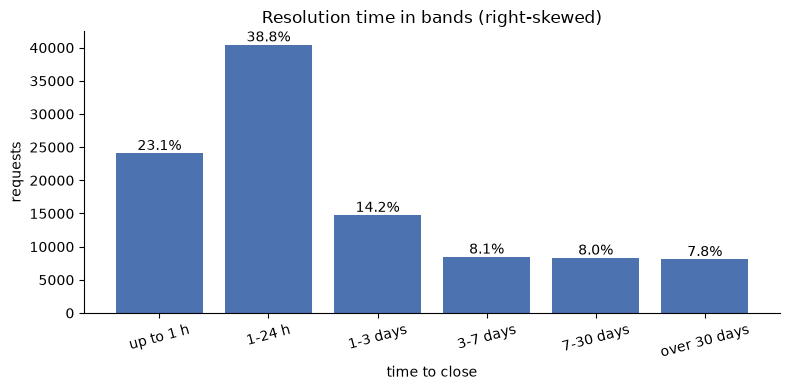

In [13]:
skew = q("""
WITH m AS (
    SELECT AVG(resolution_hours) AS mu, STDDEV_POP(resolution_hours) AS sd
    FROM service_requests WHERE resolution_hours IS NOT NULL
)
SELECT ROUND((AVG(POWER(s.resolution_hours - m.mu, 3)) / POWER(m.sd, 3))::numeric, 2) AS skewness
FROM service_requests s CROSS JOIN m
WHERE s.resolution_hours IS NOT NULL
GROUP BY m.sd
""")
bands = q("""
SELECT CASE
           WHEN resolution_hours <= 1   THEN '1  up to 1 h'
           WHEN resolution_hours <= 24  THEN '2  1-24 h'
           WHEN resolution_hours <= 72  THEN '3  1-3 days'
           WHEN resolution_hours <= 168 THEN '4  3-7 days'
           WHEN resolution_hours <= 720 THEN '5  7-30 days'
           ELSE                              '6  over 30 days'
       END AS band,
       COUNT(*) AS requests,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct
FROM service_requests
WHERE resolution_hours IS NOT NULL
GROUP BY band
ORDER BY band
""")
print("n =", bands.requests.sum())
print("skewness:", skew.skewness[0])
display(bands)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(bands.band.str[3:], bands.requests, color="#4c72b0")
ax.bar_label(bars, labels=[f"{p}%" for p in bands.pct])
ax.set_xlabel("time to close")
ax.set_ylabel("requests")
ax.set_title("Resolution time in bands (right-skewed)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Observed.** The population skewness is 6.66, so the distribution has a very long right tail. 23.1% of requests close within an hour and 38.8% between 1 and 24 hours, which means 61.9% close within a day. 14.2% take 1 to 3 days, 8.1% take 3 to 7 days, 8.0% take 7 to 30 days, and 7.8% (8,085 requests) take more than 30 days.

**Careful reading.** The bands are my own choice. They show that the 72 hour cut-off I use in the project splits the data into about 76% under and 24% over, but 72 hours is not an official service standard, and moving the line would change that share. A request can also be in the 'over 30 days' band simply because the case stayed open on paper.

## 13. Are requests concentrated in particular places?

n = 105540 | with coordinates: 103892


,borough,requests,with_coordinates,pct_with_coordinates
0,BROOKLYN,31634,31256,98.8
1,QUEENS,24954,24385,97.7
2,BRONX,24072,23850,99.1
3,MANHATTAN,20835,20531,98.5
4,STATEN ISLAND,3970,3860,97.2
5,Unspecified,75,10,13.3


,incident_address,latitude,longitude,requests
0,655 EAST 230 STREET,40.891872,-73.860168,2887


,lat_cell,lon_cell,requests
0,40.82,-73.94,906
1,40.86,-73.90,712
2,40.85,-73.91,707
3,40.82,-73.95,691
4,40.89,-73.86,685
5,40.83,-73.92,650
6,40.80,-73.95,632
7,40.65,-73.96,600
8,40.84,-73.94,586
9,40.84,-73.92,580


n in grid = 101005 | cells: 875 | top 15 cells hold 9.5 %


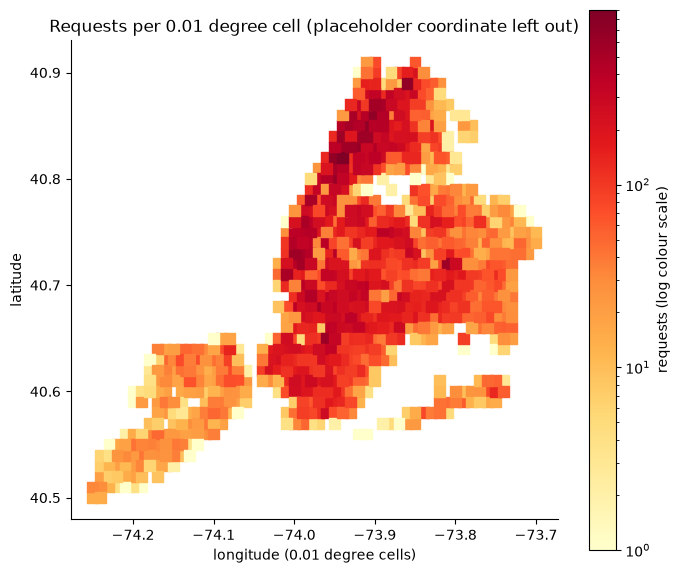

In [14]:
coverage = q("""
SELECT borough, COUNT(*) AS requests,
       COUNT(latitude) AS with_coordinates,
       ROUND(100.0 * COUNT(latitude) / COUNT(*), 1) AS pct_with_coordinates
FROM service_requests
GROUP BY borough
ORDER BY requests DESC
""")
print("n =", coverage.requests.sum(), "| with coordinates:", coverage.with_coordinates.sum())
display(coverage)

# the placeholder coordinate: one point holding thousands of rows
repeated = q("""
SELECT incident_address, latitude, longitude, COUNT(*) AS requests
FROM service_requests
WHERE flag_repeated_coords
GROUP BY incident_address, latitude, longitude
ORDER BY requests DESC
LIMIT 3
""")
display(repeated)

hot_cells = q("""
SELECT ROUND(latitude::numeric, 2) AS lat_cell, ROUND(longitude::numeric, 2) AS lon_cell,
       COUNT(*) AS requests
FROM service_requests
WHERE NOT flag_missing_coords AND NOT flag_coords_outside_nyc AND NOT flag_repeated_coords
GROUP BY lat_cell, lon_cell
ORDER BY requests DESC
LIMIT 15
""")
display(hot_cells)

# all cells for the picture, same filter as above
all_cells = q("""
SELECT ROUND(latitude::numeric, 2) AS lat_cell, ROUND(longitude::numeric, 2) AS lon_cell,
       COUNT(*) AS requests
FROM service_requests
WHERE NOT flag_missing_coords AND NOT flag_coords_outside_nyc AND NOT flag_repeated_coords
GROUP BY lat_cell, lon_cell
""")
all_cells[["lat_cell", "lon_cell"]] = all_cells[["lat_cell", "lon_cell"]].astype(float)
print("n in grid =", all_cells.requests.sum(), "| cells:", len(all_cells),
      "| top 15 cells hold", round(100 * hot_cells.requests.sum() / all_cells.requests.sum(), 1), "%")

fig, ax = plt.subplots(figsize=(7, 6))
pts = ax.scatter(all_cells.lon_cell, all_cells.lat_cell, c=all_cells.requests, s=60,
                 marker="s", cmap="YlOrRd", norm=plt.matplotlib.colors.LogNorm())
ax.set_aspect(1 / np.cos(np.radians(40.7)))
ax.set_xlabel("longitude (0.01 degree cells)")
ax.set_ylabel("latitude")
ax.set_title("Requests per 0.01 degree cell (placeholder coordinate left out)")
fig.colorbar(pts, ax=ax, label="requests (log colour scale)")
plt.tight_layout()
plt.show()

**Observed.** 103,892 of 105,540 requests (98.4%) have coordinates; coverage is above 97% in the five boroughs and low only for the 75 'Unspecified' rows (13.3%). One placeholder point, 655 East 230 Street (40.8919, -73.8602), holds 2,887 rows (2.7%), so I took it out. The remaining 101,005 requests fall into 875 cells of 0.01 degrees. The busiest cell is at latitude 40.82, longitude -73.94 with 906 requests, and the top 15 cells hold 9.5% of the gridded requests. 12 of those 15 cells lie north of latitude 40.80 (upper Manhattan and the Bronx on the map).

**Careful reading.** A 0.01 degree cell is roughly 1 km by 0.85 km, so this is a coarse view, and cells do not respect borough or neighbourhood lines. Dense cells are also where more people live, so the pattern may follow population. Exact coordinates shared by many rows suggest the 655 East 230 Street point is a police-station address used as a default; other placeholders under my 1,000-row rule could remain.

## 14. Do closure rates differ by agency or borough?

n agency rows = 105473 | n borough rows = 105540


,grouping,name,requests,closure_pct
0,agency,DHS,1334,73.7
1,agency,EDC,618,86.7
2,agency,DPR,2872,86.9
3,agency,TLC,1004,93.0
4,agency,DOHMH,2482,96.1
5,agency,DOT,6676,97.9
6,agency,DEP,5546,98.9
7,agency,DSNY,9662,99.2
8,agency,HPD,22882,99.5
9,agency,DCWP,509,99.8


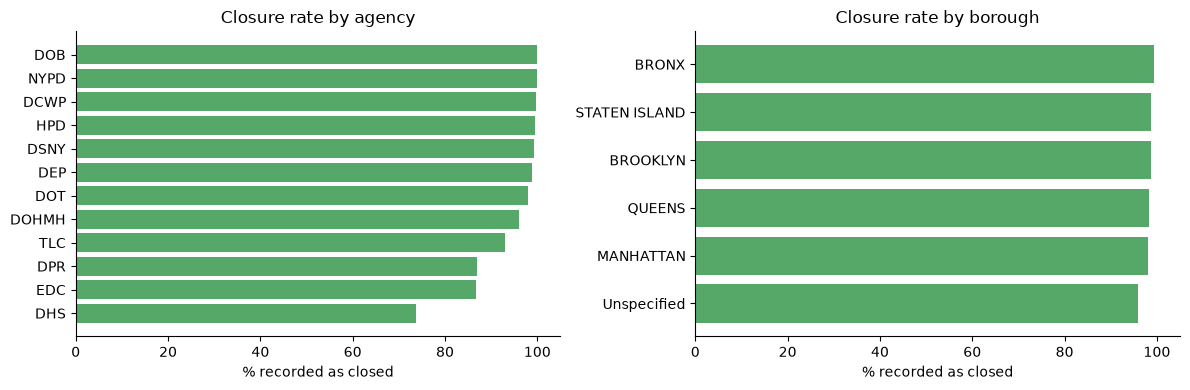

In [15]:
closure = q("""
SELECT 'agency' AS grouping, agency AS name, COUNT(*) AS requests,
       ROUND(100.0 * SUM(is_closed::int) / COUNT(*), 1) AS closure_pct
FROM service_requests
GROUP BY agency
HAVING COUNT(*) >= 100
UNION ALL
SELECT 'borough', borough, COUNT(*), ROUND(100.0 * SUM(is_closed::int) / COUNT(*), 1)
FROM service_requests
GROUP BY borough
ORDER BY grouping, closure_pct
""")
closure["closure_pct"] = closure.closure_pct.astype(float)
print("n agency rows =", closure[closure.grouping == "agency"].requests.sum(),
      "| n borough rows =", closure[closure.grouping == "borough"].requests.sum())
display(closure)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for ax, which in zip((ax1, ax2), ("agency", "borough")):
    part = closure[closure.grouping == which]
    ax.barh(part.name, part.closure_pct, color="#55a868")
    ax.set_xlabel("% recorded as closed")
    ax.set_title(f"Closure rate by {which}")
ax1.set_xlim(0, 105)
plt.tight_layout()
plt.show()

**Observed.** Closure rates by agency run from 73.7% for DHS (1,334 requests) through 86.7% for EDC and 86.9% for DPR, 93.0% for TLC and 96.1% for DOHMH, up to 99.5% for HPD and 100.0% for NYPD and DOB. Across boroughs the spread is small: 98.0% in Manhattan to 99.4% in the Bronx, with 96.0% for the 75 unspecified rows.

**Careful reading.** 'Closed' is the status and date recorded by the agency. A low closure rate may mean cases really stay open, or that the agency records the outcome differently, so it should not be read as unresolved problems. Only agencies with 100+ requests are shown (67 requests from smaller agencies are left out of the agency chart). The axis starts at zero on purpose, since the borough differences are only a point or two.

## 15. Which complaint types are both frequent and slow?

n = 102472 valid cases in 82 categories; 2 pass both cut-offs


,complaint_type,requests,median_hours
0,UNSANITARY CONDITION,3169,282.4
1,DOOR/WINDOW,1307,304.8


volume cut-off: 1154 | duration cut-off: 260.6 hours


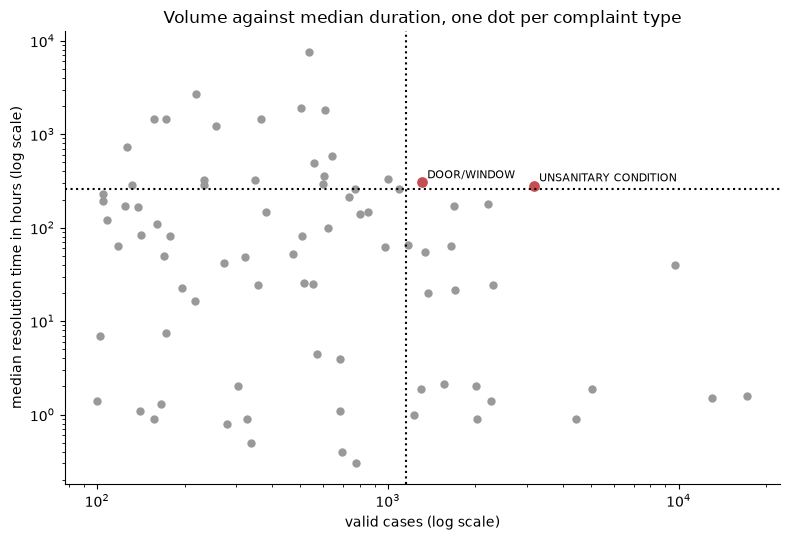

In [16]:
priority = q("""
WITH cat AS (
    SELECT complaint_type, COUNT(*) AS requests,
           PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY resolution_hours) AS median_hours
    FROM service_requests
    WHERE resolution_hours IS NOT NULL
    GROUP BY complaint_type
    HAVING COUNT(*) >= 100
), cut AS (
    SELECT PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY requests)     AS vol_cut,
           PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY median_hours) AS dur_cut
    FROM cat
)
SELECT c.complaint_type, c.requests, ROUND(c.median_hours::numeric, 1) AS median_hours
FROM cat c CROSS JOIN cut
WHERE c.requests >= cut.vol_cut AND c.median_hours >= cut.dur_cut
ORDER BY c.requests DESC
""")
print("n =", by_complaint.n.sum(), "valid cases in", len(by_complaint), "categories;",
      len(priority), "pass both cut-offs")
display(priority)

# by_complaint (task 9) has the same categories, so reuse it for the scatter
vol_cut = by_complaint.n.quantile(0.75)
dur_cut = by_complaint.median_hours.quantile(0.75)
print("volume cut-off:", round(vol_cut), "| duration cut-off:", round(dur_cut, 1), "hours")

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(by_complaint.n, by_complaint.median_hours, color="#999999", s=25)
hit = by_complaint[by_complaint.complaint_type.isin(priority.complaint_type)]
ax.scatter(hit.n, hit.median_hours, color="#c44e52", s=45)
for _, r in hit.iterrows():
    ax.annotate(r.complaint_type, (r.n, r.median_hours), fontsize=8, xytext=(4, 3), textcoords="offset points")
ax.axvline(vol_cut, color="black", linestyle=":")
ax.axhline(dur_cut, color="black", linestyle=":")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("valid cases (log scale)")
ax.set_ylabel("median resolution time in hours (log scale)")
ax.set_title("Volume against median duration, one dot per complaint type")
plt.tight_layout()
plt.show()

**Observed.** Both cut-offs are the 75th percentile across the 82 categories: at least 1,154 valid cases and a median of at least 260.6 hours. Only two types pass: UNSANITARY CONDITION (3,169 cases, median 282.4 hours) and DOOR/WINDOW (1,307 cases, median 304.8 hours). The biggest categories, such as Illegal Parking (17,251 cases, median 1.6 hours) and Noise - Residential (13,022, 1.5 hours), are fast, and HEAT/HOT WATER (9,712 cases, median 39.8 hours) is in between. The slowest types, like Noise - Helicopter, have few cases.

**Careful reading.** Using the 75th percentile twice is a rule I picked; a different cut would give another list (PLUMBING with 2,216 cases and a median of 180.8 hours just misses the duration line). Both items are housing complaints handled by one agency, which closes through inspections, so slow here may reflect the process. This is a way to point at categories worth a closer look, not a result about which are failing.

## Summary

What I take from the sample: demand is concentrated (ten complaint types make up 58.4% of requests, and NYPD, HPD and DSNY about 77%), it is a bit lower on weekends, and more than half of it is created during office hours. Resolution time is very skewed: the median is 7.8 hours, the mean 261.8, and 23.9% of requests are over 72 hours. The long durations come mostly from housing agencies, building inspections and a few special categories, while most parking and noise requests close within a couple of hours.

What I would not claim: that any borough or agency is better or worse, that closed means solved, or that the pattern holds for a full year. Those need population figures, data on the outcome of each request, and a longer period.